> ⚡ **GPU version** of [5_Variogram_interpolation_comparison.ipynb](5_Variogram_interpolation_comparison.ipynb). Only the kriging and simulation calls change: they run
> through `gstatsim_gpu` with `backend=BACKEND` and are timed with `%%time`. Text, data, seeds and
> plots are the original demo's, so the results match it (to rounding).
>
> Needs an NVIDIA GPU and `pip install gstatsim[gpu]`. Without a GPU, `BACKEND` is set to `"cpu"`,
> which runs GStatSim itself.

In [1]:
# GPU version: use the GPU if there is one; otherwise "cpu" runs GStatSim itself
import gstatsim_gpu as gsg

BACKEND = "gpu" if gsg.gpu_status().available else "cpu"
print("Backend:", BACKEND, "|", gsg.gpu_status().device_name or gsg.gpu_status().reason)

C:\Users\alexi\miniforge3\envs\gstatsim-gpu\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Backend: gpu | NVIDIA GeForce RTX 5060 Laptop GPU


# Interpolation comparison using different variogram models

Earlier we saw that there are different types of variogram models with different shapes. In this script, we'll use a synthetic example to explore how the variogram model affects the interpolation. For this example, we need to use GStools (https://github.com/GeoStat-Framework/GSTools) to generate an example data set. 

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import QuantileTransformer 
import gstatsim as gs
import skgstat as skg
from skgstat import models
import random
import gstools as gst
from copy import deepcopy

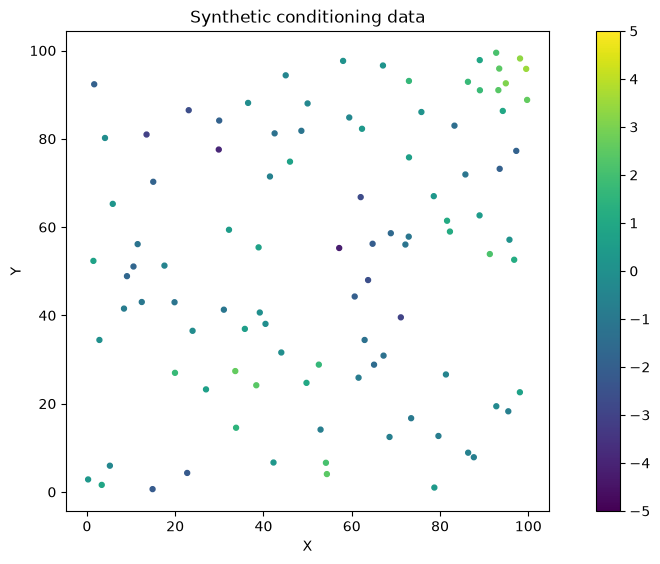

In [3]:
# create random conditioning data using GSTools
rng = np.random.default_rng(seed=0)
x = rng.random(100) * 100.
y = rng.random(100) * 100.
model = gst.Gaussian(dim=2, var=2, len_scale =8)
srf = gst.SRF(model, mean=0, seed=300000)
field = srf((x,y))

# plot synthetic conditioning data
fig = plt.figure()
im = plt.scatter(x,y, c = field, vmin = -5, vmax = 5, marker=".", s = 50)       # scatter plot for location map
plt.title('Synthetic conditioning data')                                    # add plot title
plt.xlabel('X'); plt.ylabel('Y')                          # set axis labels
cbar = plt.colorbar(im, orientation="vertical", ticks=np.linspace(-5, 5, 11)) # add vertical color bar
plt.subplots_adjust(left=0.0, bottom=0.0, right=1.0, top=1.0) # adjust the plot size
plt.axis('scaled')
plt.show()

In [4]:
# make dataframe
data = np.transpose([x,y,field])
df = pd.DataFrame(data, columns = ['X','Y','Z'])
df.head()

,X,Y,Z
0,63.696169,47.998792,-2.616795
1,26.978671,23.237292,0.643507
2,4.097352,80.188058,-0.136528
3,1.652764,92.353016,-1.949774
4,81.327024,26.613027,-0.503876


In [5]:
# compute experimental variogram

coords = np.column_stack((x, y))
maxlag = 100      # maximum range distance
n_lags = 20         # num of bins

# compute variogram
V1 = skg.Variogram(coords, field, bin_func='even', n_lags=n_lags, maxlag=maxlag, normalize=False)

## Fit variogram models

In [6]:
V1.model = 'gaussian' 
V1.parameters

[np.float64(31.913603797208136), np.float64(2.683696081573943), 0]

In [7]:
V2 = deepcopy(V1)
V2.model = 'exponential' 
V2.parameters

[np.float64(49.53227607034486), np.float64(2.7836093199190177), 0]

In [8]:
V3 = deepcopy(V1)
V3.model = 'spherical'
V3.parameters

[np.float64(34.89438036897665), np.float64(2.675579446334155), 0]

In [9]:
V4 = deepcopy(V1)
V4.model = 'matern' 
V4.parameters

[np.float64(32.28416026452797),
 np.float64(2.6866425113625008),
 np.float64(19.999999999984613),
 0]

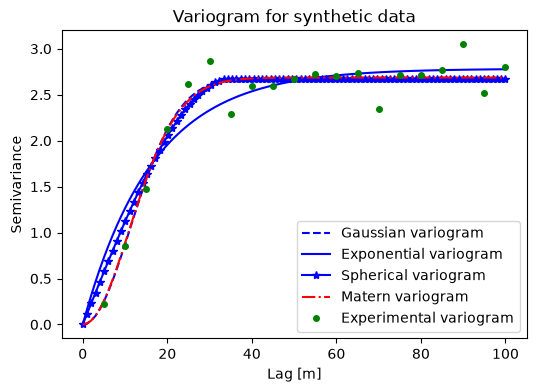

In [10]:
# plot variograms

# extract experimental variogram values
xdata = V1.bins
ydata = V1.experimental

# evaluate models
xi = np.linspace(0, xdata[-1], 100) 
y_gauss = models.gaussian(xi, *V1.parameters)
y_exp = models.exponential(xi, *V2.parameters)
y_sph = models.spherical(xi, *V3.parameters)
y_matern = models.matern(xi, *V4.parameters)

# plot variogram model
fig = plt.figure(figsize=(6,4))
plt.plot(xi, y_gauss,'b--', label='Gaussian variogram')
plt.plot(xi, y_exp,'b-', label='Exponential variogram')
plt.plot(xi, y_sph,'b*-', label='Spherical variogram')
plt.plot(xi, y_matern, 'r-.', label='Matern variogram')
plt.plot(xdata, ydata,'og', markersize=4, label='Experimental variogram')
plt.title('Variogram for synthetic data')
plt.xlabel('Lag [m]'); plt.ylabel('Semivariance')  
plt.legend(loc='lower right')
plt.show()

## Initialize grid

Make list of grid cells that need to be simulated.

In [11]:
# define coordinate grid
xmin = 0; xmax = 100     # min and max x values
ymin = 0; ymax = 100     # min and max y values
res = 1

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)

## Sequential Gaussian simulation

In this example we use okrige_sgs.

In [12]:
# set variogram parameters
azimuth = 0
nugget = V1.parameters[2]

# save variogram parameters as a list
vtype = 'Gaussian'
vario1 = [azimuth, V1.parameters[2], V1.parameters[0], V1.parameters[0], V1.parameters[1], vtype]

vtype = 'Exponential'
vario2 = [azimuth, V2.parameters[2], V2.parameters[0], V2.parameters[0], V2.parameters[1], vtype]

vtype = 'Spherical'
vario3 = [azimuth, V3.parameters[2], V3.parameters[0], V3.parameters[0], V3.parameters[1], vtype]

# add in the smoothness parameter for the Matern covariance
vtype = 'Matern'
vario4 = [azimuth, V4.parameters[-1], V4.parameters[0], V4.parameters[0], V4.parameters[1], vtype, V4.parameters[2]]

k = 48      # number of neighboring data points used to estimate a given point 
rad = 50    # search radius

In [13]:
%%time
# GPU version: vario4 is a Matern model, which has no GPU version yet, so it runs on the CPU
# GPU version: vario1 is Gaussian with no nugget, so on this 1-unit grid the kriging systems are numerically singular. GStatSim solves them by least squares, which GPU SGS can't do mid-simulation, so this one runs on the CPU
# simulation

sim_gauss = gsg.sgs(df, Pred_grid_xy, vario1, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', seed=rng, backend="cpu") 

sim_exp = gsg.sgs(df, Pred_grid_xy, vario2, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', seed=rng, backend=BACKEND) 

sim_sph = gsg.sgs(df, Pred_grid_xy, vario3, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', seed=rng, backend=BACKEND)

sim_matern = gsg.sgs(df, Pred_grid_xy, vario4, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', seed=rng, backend="cpu")

CPU times: total: 3min 58s
Wall time: 4min 6s


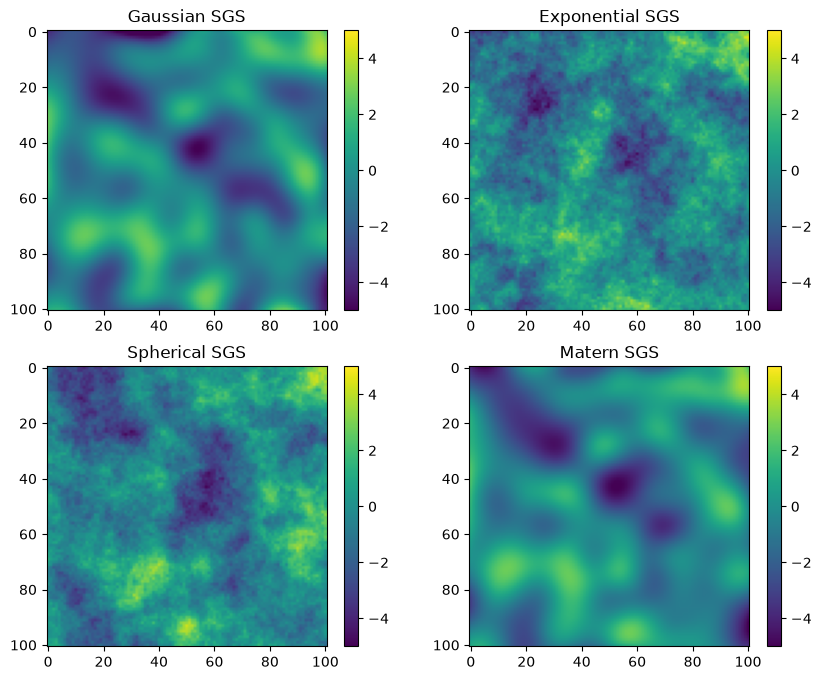

In [14]:
vmax = 5
vmin = -vmax

fig, axs = plt.subplots(2, 2, figsize=(10, 8))

sims = [sim_gauss, sim_exp, sim_sph, sim_matern]
titles = ['Gaussian SGS', 'Exponential SGS', 'Spherical SGS', 'Matern SGS']

for ax, sim, title in zip(axs.flatten(), sims, titles):
    im = ax.imshow(sim.reshape(101,101), vmin=vmin, vmax=vmax)
    ax.set_title(title)
    plt.colorbar(im, ax=ax)

plt.show()

Here we can see that SGS with different variogram models has different spatial characteristics. For example, the Gaussian SGS realization is very smooth because the Gaussian variogram model is nearly zero at small lags. 

In [15]:
%%time
# GPU version: vario4 is a Matern model, which has no GPU version yet, so it runs on the CPU
k = 128      # number of neighboring data points used to estimate a given point 
rad = 100

# kriging
krige_gauss, var_gauss = gsg.predict(df, Pred_grid_xy, vario1, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', backend=BACKEND) 

krige_exp, var_exp = gsg.predict(df, Pred_grid_xy, vario2, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', backend=BACKEND) 

krige_sph, var_sph = gsg.predict(df, Pred_grid_xy, vario3, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', backend=BACKEND)

krige_matern, var_matern = gsg.predict(df, Pred_grid_xy, vario4, num_points=k, radius=rad, method='ordinary', xx='X', yy='Y', zz='Z', backend="cpu") 

CPU times: total: 2min 22s
Wall time: 2min 27s


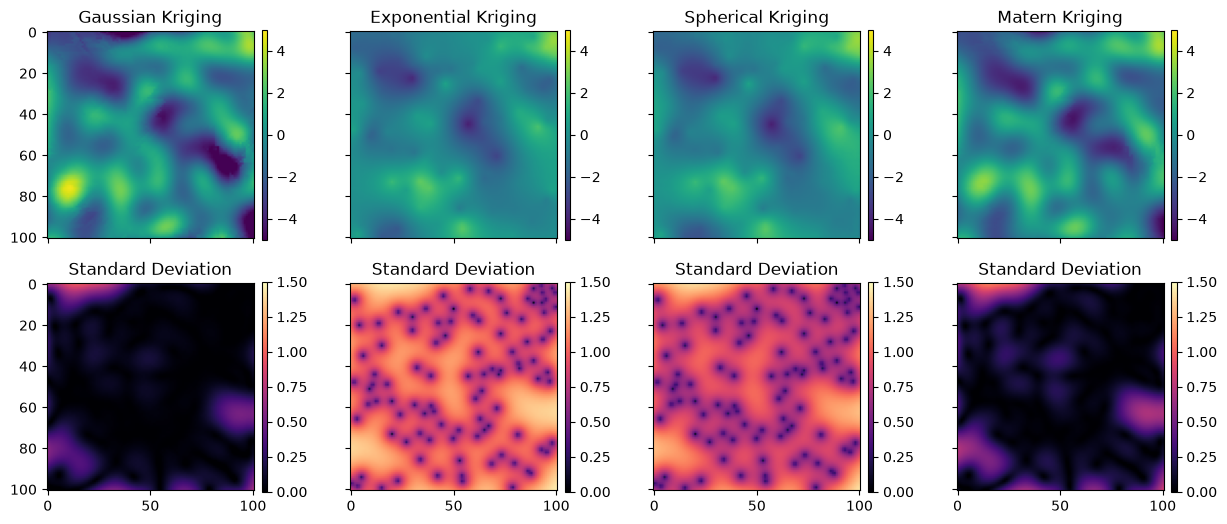

In [16]:
# kriging plots
vmax = 5
vmin = -vmax

fig, axs = plt.subplots(2, 4, figsize=(15,6), sharey=True, sharex=True)

plots = [
    [krige_gauss, var_gauss],
    [krige_exp, var_exp],
    [krige_sph, var_sph],
    [krige_matern, var_matern]
]
titles = ['Gaussian', 'Exponential', 'Spherical', 'Matern']

for row, plot, title in zip(axs.T, plots, titles):
    im = row[0].imshow(plot[0].reshape(101, 101), vmin=vmin, vmax=vmax)
    row[0].set_title(title + ' Kriging')
    plt.colorbar(im, ax=row[0], pad=0.03, aspect=40)
    im = row[1].imshow(np.sqrt(plot[1].reshape(101, 101)), vmin=0, vmax=1.5, cmap='magma')
    row[1].set_title('Standard Deviation')
    plt.colorbar(im, ax=row[1], pad=0.03, aspect=40)

plt.show()

The different kriging results are fairly similar, but the uncertainties are much lower for the Gaussian model and greater for the Exponential model. So using the wrong variogram model type could cause you to overestimate or underestimate the uncertainty.

To choose the right variogram model, you can compare the different variogram models to the experimental variogram to see which one fits best. In some cases, the best choice might be unclear. It is also important to consider the geological phenomena you are modeling and the type of spatial structure it has. For example, if you are modeling a geological condition that you know is smoothly varying, then you would most likely want to use a Gaussian variogram.

Download the tutorial {Download}`here<./5_Variogram_interpolation_comparison.ipynb>`.